# 03 - Cancellation Prediction & Model Evaluation

## Dataset
Hotel Booking Demand dataset  
**Source:** [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

The target variable is `is_canceled` (`1` = canceled, `0` = not canceled).

## Objective
Compare classification models for predicting booking cancellations. Evaluate
them with precision, recall, F1-score, and ROC-AUC, and use cross-validation
and hyperparameter search to assess model performance.

In [3]:
import os
print(os.getcwd())

C:\Users\aizat\Downloads\DATA MINING 2026


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [5]:
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)


In [9]:
df = pd.read_csv("hotel_bookings.csv")

In [18]:
pd.set_option("display.max_columns", None)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [11]:
df.shape

(119390, 32)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [13]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [14]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [19]:
# Select the target column
target_column = "is_canceled"

X = df.drop(columns=[target_column,
                     "reservation_status",
                     "reservation_status_date",
                    "agent",
                    "company"])
y = df[target_column]


# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [21]:
#preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numeric and categorical input columns
numeric_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)


Numeric columns: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical columns: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type']


In [23]:
# Numeric: fill missing values, then scale
#only children column
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: fill missing values, then encode
#only country column
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply each pipeline to its corresponding columns
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

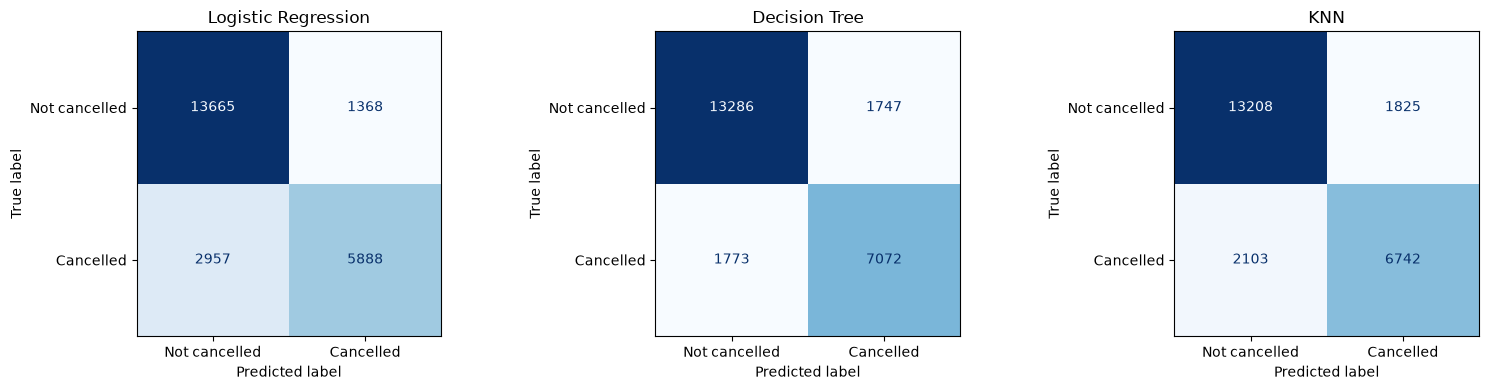

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8189,0.8115,0.6657,0.7314,0.8964
Decision Tree,0.8526,0.8019,0.7995,0.8007,0.8442
KNN,0.8355,0.7870,0.7622,0.7744,0.9000


In [24]:
#TASK1
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, classifier) in zip(axes, models.items()):

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    # Fit preprocessing and classifier using training data only
    model.fit(X_train, y_train)

    # Predict classes and probabilities on the test set
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_probability)
    })

    trained_models[name] = model

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not cancelled", "Cancelled"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

We compared Logistic Regression, Decision Tree, and KNN using the same training and test sets. Decision Tree achieved the highest accuracy (0.8526), recall (0.7995), and F1-score (0.8007). Logistic Regression had the highest precision (0.8115), while KNN achieved the highest ROC-AUC (0.9000).

Precision measures how many predicted cancellations were correct, while recall measures how many actual cancellations were detected. F1 combines precision and recall. We selected F1 as the main metric because both false cancellation alerts and missed cancellations matter. Based on test F1, Decision Tree was the strongest of the three baseline models.

In [25]:
#TASK2
depths = [1, 2, 3, 5, 10, None]
depth_results = []

for depth in depths:

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    depth_results.append({
        "Max depth": str(depth),
        "Training accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Testing accuracy": accuracy_score(
            y_test, test_predictions
        )
    })

depth_results_df = pd.DataFrame(depth_results)

depth_results_df["Accuracy gap"] = (
    depth_results_df["Training accuracy"]
    - depth_results_df["Testing accuracy"]
)

display(depth_results_df.round(4))

,Max depth,Training accuracy,Testing accuracy,Accuracy gap
0,1,0.7507,0.7481,0.0026
1,2,0.7511,0.7485,0.0026
2,3,0.7580,0.7558,0.0022
3,5,0.7967,0.7983,-0.0016
4,10,0.8436,0.8389,0.0047
5,None,0.9963,0.8526,0.1437


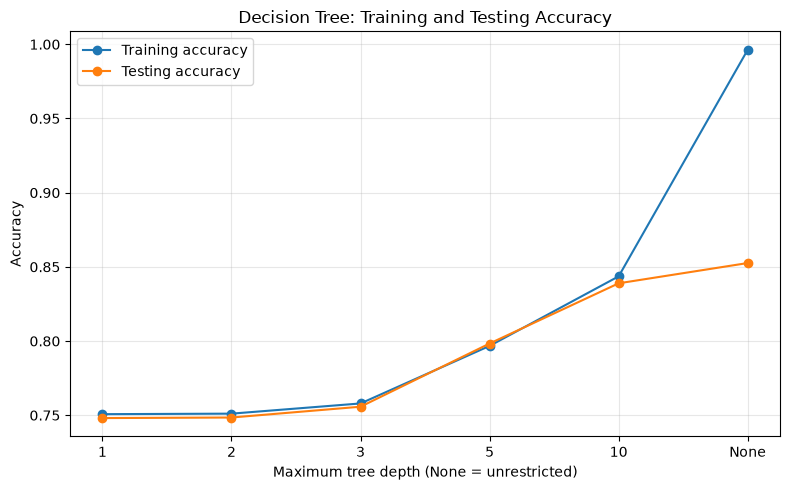

In [26]:
positions = range(len(depths))

plt.figure(figsize=(8, 5))

plt.plot(
    positions,
    depth_results_df["Training accuracy"],
    marker="o",
    label="Training accuracy"
)

plt.plot(
    positions,
    depth_results_df["Testing accuracy"],
    marker="o",
    label="Testing accuracy"
)

plt.xticks(positions, depth_results_df["Max depth"])
plt.xlabel("Maximum tree depth (None = unrestricted)")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training and Testing Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Highest observed test accuracy: None.
A simpler tree with a much smaller training–test gap: depth 10.

Trees with depths 1–3 show underfitting because both training and testing accuracy are relatively low and improve as depth increases. 
At depth 10, training accuracy is 84.36% and testing accuracy is 83.89%, giving a small gap. 

The unrestricted tree shows overfitting: training accuracy reaches 99.63%, while testing accuracy is 85.26%. Although it achieves the highest test accuracy among the tested depths, its much larger gap suggests that it fits patterns specific to the training data.

In [28]:
#TASK3
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Keep approximately the same class proportions in each fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_cv = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

# Evaluate F1 across the five folds
cv_scores = cross_val_score(
    model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("F1 for each fold:", cv_scores.round(4))
print("Mean F1:", cv_scores.mean().round(4))
print("Standard deviation:", cv_scores.std().round(4))

F1 for each fold: [0.7753 0.7649 0.7663 0.7775 0.7833]
Mean F1: 0.7735
Standard deviation: 0.0069


The Decision Tree with max_depth=10 achieved a mean F1-score of 0.7735 across five stratified folds. Individual scores ranged from 0.7649 to 0.7833, with a standard deviation of 0.0069. This small variation suggests consistent performance across these validation splits. Preprocessing was fitted separately within each fold through the pipeline, preventing information from the validation portion from influencing preprocessing. These results describe the depth-10 model; they do not yet establish which hyperparameter combination is best.

In [29]:
#TASK4
from time import perf_counter

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

# Preprocessing will be fitted separately within each CV fold
search_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_space = {
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 10, 30],
    "classifier__min_samples_leaf": [1, 5, 20]
}

In [30]:
grid_search = GridSearchCV(
    estimator=search_model,
    param_grid=param_space,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start

print("Grid search best parameters:")
print(grid_search.best_params_)
print("Best mean CV F1:", round(grid_search.best_score_, 4))
print("Runtime (seconds):", round(grid_seconds, 2))

Grid search best parameters:
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best mean CV F1: 0.7951
Runtime (seconds): 162.02


In [31]:
random_search = RandomizedSearchCV(
    estimator=search_model,
    param_distributions=param_space,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start

print("Randomized search best parameters:")
print(random_search.best_params_)
print("Best mean CV F1:", round(random_search.best_score_, 4))
print("Runtime (seconds):", round(random_seconds, 2))

Randomized search best parameters:
{'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 15}
Best mean CV F1: 0.7937
Runtime (seconds): 66.84


In [32]:
search_comparison = pd.DataFrame([
    {
        "Search": "GridSearchCV",
        "Possible configurations": 36,
        "Configurations evaluated": len(grid_search.cv_results_["params"]),
        "CV fits": len(grid_search.cv_results_["params"]) * 5,
        "Best mean CV F1": grid_search.best_score_,
        "Runtime (seconds)": grid_seconds,
        "Best parameters": grid_search.best_params_
    },
    {
        "Search": "RandomizedSearchCV",
        "Possible configurations": 36,
        "Configurations evaluated": len(random_search.cv_results_["params"]),
        "CV fits": len(random_search.cv_results_["params"]) * 5,
        "Best mean CV F1": random_search.best_score_,
        "Runtime (seconds)": random_seconds,
        "Best parameters": random_search.best_params_
    }
])

display(search_comparison.round(4))

,Search,Possible configurations,Configurations evaluated,CV fits,Best mean CV F1,Runtime (seconds),Best parameters
0,GridSearchCV,36,36,180,0.7951,162.0223,"{'classifier__max_depth': 15, 'classifier__min..."
1,RandomizedSearchCV,36,12,60,0.7937,66.8355,"{'classifier__min_samples_split': 2, 'classifi..."


In [33]:
for name, search in [
    ("GridSearchCV", grid_search),
    ("RandomizedSearchCV", random_search)
]:
    print(name)

    top_results = (
        pd.DataFrame(search.cv_results_)
        .sort_values("rank_test_score")
        [["params", "mean_test_score", "std_test_score", "rank_test_score"]]
        .head(5)
    )

    display(top_results)

GridSearchCV


,params,mean_test_score,std_test_score,rank_test_score
18,"{'classifier__max_depth': 15, 'classifier__min...",0.795145,0.003986,1
27,"{'classifier__max_depth': None, 'classifier__m...",0.794761,0.002609,2
19,"{'classifier__max_depth': 15, 'classifier__min...",0.794759,0.004720,3
21,"{'classifier__max_depth': 15, 'classifier__min...",0.793665,0.004251,4
22,"{'classifier__max_depth': 15, 'classifier__min...",0.793665,0.004251,4


RandomizedSearchCV


,params,mean_test_score,std_test_score,rank_test_score
6,"{'classifier__min_samples_split': 2, 'classifi...",0.793665,0.004251,1
2,"{'classifier__min_samples_split': 30, 'classif...",0.790025,0.005368,2
3,"{'classifier__min_samples_split': 2, 'classifi...",0.788479,0.004631,3
5,"{'classifier__min_samples_split': 10, 'classif...",0.788479,0.004631,3
0,"{'classifier__min_samples_split': 30, 'classif...",0.787399,0.005412,5


In [34]:
if random_search.best_score_ > grid_search.best_score_:
    selected_search = random_search
    selected_name = "RandomizedSearchCV"
else:
    selected_search = grid_search
    selected_name = "GridSearchCV"

best_model = selected_search.best_estimator_

print("Selected search:", selected_name)
print("Selected parameters:", selected_search.best_params_)

Selected search: GridSearchCV
Selected parameters: {'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}


Why must we avoid selecting hyperparameters using the test set?

The test set should estimate performance on unseen data. If we repeatedly use its scores to choose settings, those choices become adapted to that particular test set, making the reported performance overly optimistic. We therefore select settings using cross-validation on the training data.

In [36]:
# Default tree: no maximum depth
default_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

default_model.fit(X_train, y_train)

# best_model is the already-trained winner selected earlier
test_results = []

for name, model in [
    ("Default Decision Tree", default_model),
    ("Tuned Decision Tree", best_model)
]:
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_comparison = pd.DataFrame(test_results).set_index("Model")
display(test_comparison.round(4))

difference = (
    test_comparison.loc["Tuned Decision Tree", "F1"]
    - test_comparison.loc["Default Decision Tree", "F1"]
)

print(f"Test F1 change: {difference * 100:+.2f} percentage points")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Default Decision Tree,0.8526,0.8019,0.7995,0.8007,0.8442
Tuned Decision Tree,0.8532,0.8234,0.7685,0.7950,0.9199


Test F1 change: -0.58 percentage points


GridSearchCV evaluated all 36 configurations using 180 cross-validation fits, taking 162.02 seconds. RandomizedSearchCV evaluated 12 configurations using 60 fits, taking 66.84 seconds. Grid search achieved a slightly higher mean CV F1 (0.7951 versus 0.7937), while randomized search required less computation.

The selected Decision Tree used max_depth=15, min_samples_split=2, and min_samples_leaf=1. Its test F1 was 0.7950, compared with 0.8007 for the default tree. Tuning improved accuracy, precision, and ROC-AUC, but reduced recall and F1. Therefore, tuning did not improve our chosen metric on this test set.

Hyperparameters must be selected using training-data cross-validation. Selecting them using test results would adapt our choices to the test set and make it less reliable as an estimate of performance on unseen data.

In [37]:
#TASK5
# Select three booking channels
segments = ["Direct", "Online TA", "Offline TA/TO"]

anova_data = df.loc[
    df["market_segment"].isin(segments),
    ["market_segment", "adr"]
].dropna()

# Calculate group statistics
group_stats = (
    anova_data.groupby("market_segment")["adr"]
    .agg(["mean", "std", "count"])
    .rename(columns={
        "mean": "Mean ADR",
        "std": "Standard deviation",
        "count": "Sample size"
    })
)

display(group_stats.round(2))

,Mean ADR,Standard deviation,Sample size
market_segment,,,
Direct,115.45,59.28,12606
Offline TA/TO,87.35,47.97,24219
Online TA,117.20,48.85,56477


In [38]:
from scipy.stats import f_oneway

direct = anova_data.loc[
    anova_data["market_segment"] == "Direct", "adr"
]

offline = anova_data.loc[
    anova_data["market_segment"] == "Offline TA/TO", "adr"
]

online = anova_data.loc[
    anova_data["market_segment"] == "Online TA", "adr"
]

F_statistic, p_value = f_oneway(direct, offline, online)

print(f"F-statistic: {F_statistic:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("Reject H₀: at least one population mean differs.")
else:
    print("Fail to reject H₀: insufficient evidence that the means differ.")

F-statistic: 3111.2203
p-value: 0.0000e+00
Reject H₀: at least one population mean differs.


One-way ANOVA found evidence that mean daily room rates differ among the three booking channels (F = 3111.22, p < 0.001). At the 0.05 significance level, we reject the hypothesis that all population means are equal. This indicates that at least one mean differs; it does not establish that every pair differs.

In [39]:
#TASK7
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import f_classif

# Select numeric input features
X_train_num = X_train.select_dtypes(include="number")

# Fill missing values using training medians
imputer_anova = SimpleImputer(strategy="median")
X_train_num_filled = imputer_anova.fit_transform(X_train_num)

# Compare each feature across cancellation classes
F_values, p_values = f_classif(X_train_num_filled, y_train)

anova_results = pd.DataFrame({
    "Feature": X_train_num.columns,
    "F_statistic": F_values,
    "p_value": p_values
}).sort_values("F_statistic", ascending=False)

display(anova_results)

,Feature,F_statistic,p_value
0,lead_time,8971.713413,0.000000e+00
16,total_of_special_requests,5681.663962,0.000000e+00
15,required_car_parking_spaces,3760.791544,0.000000e+00
12,booking_changes,1962.271615,0.000000e+00
10,previous_cancellations,1202.892310,6.174691e-262
9,is_repeated_guest,715.777585,4.226288e-157
6,adults,321.861507,7.475807e-72
11,previous_bookings_not_canceled,313.550391,4.764721e-70
13,days_in_waiting_list,275.182957,1.027749e-61
14,adr,203.829409,3.402762e-46


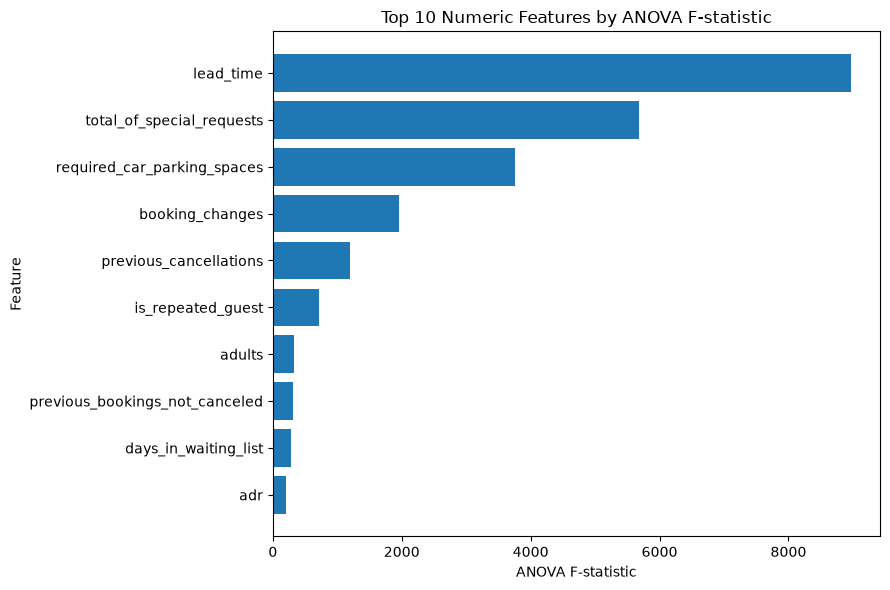

In [40]:
top_10 = anova_results.head(10).sort_values("F_statistic")

plt.figure(figsize=(9, 6))
plt.barh(top_10["Feature"], top_10["F_statistic"])
plt.xlabel("ANOVA F-statistic")
plt.ylabel("Feature")
plt.title("Top 10 Numeric Features by ANOVA F-statistic")
plt.tight_layout()
plt.show()

In [41]:
significant_features = anova_results[
    anova_results["p_value"] < 0.05
]

display(significant_features)

,Feature,F_statistic,p_value
0,lead_time,8971.713413,0.000000e+00
16,total_of_special_requests,5681.663962,0.000000e+00
15,required_car_parking_spaces,3760.791544,0.000000e+00
12,booking_changes,1962.271615,0.000000e+00
10,previous_cancellations,1202.892310,6.174691e-262
9,is_repeated_guest,715.777585,4.226288e-157
6,adults,321.861507,7.475807e-72
11,previous_bookings_not_canceled,313.550391,4.764721e-70
13,days_in_waiting_list,275.182957,1.027749e-61
14,adr,203.829409,3.402762e-46


We compared the average values of 17 numeric features between cancelled and non-cancelled bookings using the training data.

lead_time, total_of_special_requests, and required_car_parking_spaces had the highest F-scores. They showed the clearest differences between the two groups.

For 15 features, the p-value was below 0.05, providing evidence that their averages differ between the groups. For children and stays_in_weekend_nights, the evidence was too weak to conclude that their averages differ.

Features with high F-scores are useful candidates for prediction. Their actual value to a model should be checked using cross-validation, because some features may provide similar information.

In [42]:
#TASK 8
from sklearn.feature_selection import SelectKBest, f_classif

X_train_num = X_train.select_dtypes(include="number")
X_test_num = X_test[X_train_num.columns]

# Model using all numeric features
all_features_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Model that selects numeric features
selection_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_classif)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [43]:
C_values = [0.01, 0.1, 1, 10, 100]

all_search = GridSearchCV(
    all_features_pipeline,
    param_grid={"classifier__C": C_values},
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

selection_search = GridSearchCV(
    selection_pipeline,
    param_grid={
        "select__k": [5, 10, 15, "all"],
        "classifier__C": C_values
    },
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

all_search.fit(X_train_num, y_train)
selection_search.fit(X_train_num, y_train)

for name, search in [
    ("All numeric features", all_search),
    ("ANOVA feature selection", selection_search)
]:
    print(name)
    print("Best parameters:", search.best_params_)
    print("Best mean CV F1:", round(search.best_score_, 4))
    print()

All numeric features
Best parameters: {'classifier__C': 10}
Best mean CV F1: 0.5829

ANOVA feature selection
Best parameters: {'classifier__C': 0.1, 'select__k': 15}
Best mean CV F1: 0.5835



In [44]:
task8_results = []

for name, search in [
    ("All numeric features", all_search),
    ("ANOVA feature selection", selection_search)
]:
    model = search.best_estimator_

    y_pred = model.predict(X_test_num)
    y_prob = model.predict_proba(X_test_num)[:, 1]

    task8_results.append({
        "Model": name,
        "Mean CV F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob)
    })

task8_comparison = pd.DataFrame(task8_results).set_index("Model")
display(task8_comparison.round(4))

# Show which features the selection pipeline kept
selector = selection_search.best_estimator_.named_steps["select"]
selected_features = X_train_num.columns[selector.get_support()]

print("Selected features:", selected_features.tolist())

,Mean CV F1,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
Model,,,,,,
All numeric features,0.5829,0.7379,0.7072,0.4992,0.5852,0.7952
ANOVA feature selection,0.5835,0.7385,0.7081,0.5001,0.5862,0.7949


Selected features: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_week_nights', 'adults', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


We compared Logistic Regression using all 17 numeric features with a pipeline that selected features using ANOVA. Five-fold cross-validation selected 15 features and C=0.1. The all-feature model’s best setting was C=10.

The feature-selection pipeline achieved a slightly higher mean CV F1 (0.5835 versus 0.5829) and test F1 (0.5862 versus 0.5852). It used two fewer features while maintaining similar performance. The benefit was small: test F1 increased by about 0.10 percentage points. Both feature selection and the change in C may have contributed to this difference.

The selected model removed children and stays_in_weekend_nights.